Some relevant physical questions you might want to tackle include:

- Does the distribution contain different sub-populations? How many?
- What's the threshold between the classes?
- If you try two clustering methods, do you get more or less the same?
- How do methods respond to outliers?
- What variable(s) shows the multi-modality more evidently?
- Are all GRBs equally likely to be observed? 

In [8]:
#L14 exercise work with gamma rays 

import numpy as np
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn import preprocessing
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from sklearn.mixture import GaussianMixture
from sklearn.metrics import confusion_matrix

In [2]:
import requests

# Download file
r = requests.get('https://user-web.icecube.wisc.edu/~grbweb_public/Summary_table.txt')
with open("Summary_table.txt", 'wb') as f:
    f.write(r.content)

# Read content
data = np.loadtxt("Summary_table.txt", dtype='str',unpack='True')

# Read headers
with open("Summary_table.txt",'r') as f:
    names = np.array([n.strip().replace(" ","_") for n in f.readlines()[1].replace("#","").replace("\n","").lstrip().split('    ') if n.strip()!=''])

In [3]:
print(data,names)

[['GRB261111A' 'GRB261110A' 'GRB261109A*' ... 'GRB910424A*' 'GRB910423A*'
  'GRB910421A*']
 ['GRB261111477' 'None' 'GRB261109049' ... 'None' 'None' 'None']
 ['11:26:34.155' '11:50:00' '1:10:18.803' ... '19:43:25.064'
  '19:51:15.804' '9:14:03.800']
 ...
 ['139.2670' '-999' '77.5700' ... '3.1360' '208.5760' '5.6960']
 ['True' 'False' 'True' ... 'False' 'False' 'False']
 ['61355.47678420' '61354.49305556' '61353.04882874' ... '48370.82181787'
  '48369.82726625' '48367.38476620']] ['GRB_name' 'GRB_name_Fermi' 'T0' 'ra' 'decl' 'pos_error' 'T90'
 'T90_error' 'T90_start' 'fluence' 'fluence_error' 'redshift' "'T100'"
 'GBM_located' 'mjd_(T0)']


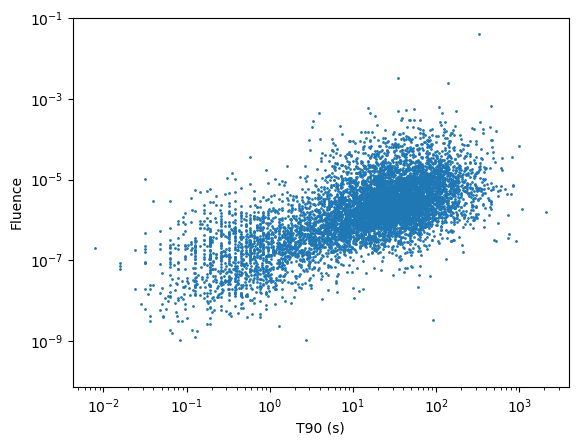

In [4]:
plt.scatter(data[6].astype(float),data[9].astype(float), s=1)
plt.xlabel("T90 (s)")
plt.ylabel("Fluence")
plt.yscale("log")
plt.xscale("log")
plt.show()

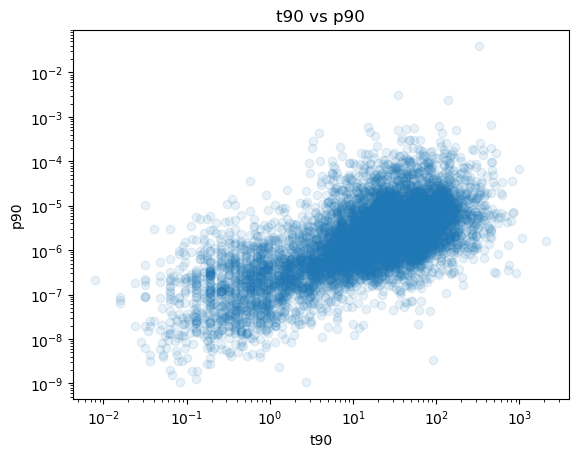

In [5]:
x = data[6].astype(float)
y = data[9].astype(float)

mask = (x > 0.0) & (y > 0.0)

x_masked = x[mask]
y_masked = y[mask]

plt.scatter(x_masked,y_masked,alpha = 0.1)
plt.title("t90 vs p90")
plt.xscale('log')
plt.yscale('log')
plt.xlabel("t90")
plt.ylabel("p90")

plt.show()
        

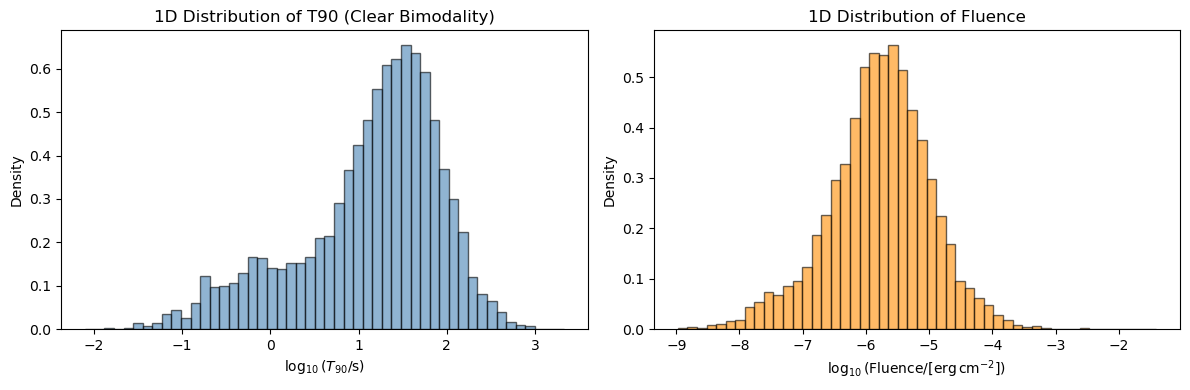

In [9]:
# Trasformazione in log10 dei dati puliti
log_x_mask = np.log10(x_masked)  # log10(T90)
log_y_mask = np.log10(y_masked)  # log10(Fluence)

# Confronto istogrammi 1D: T90 mostra la bimodalità molto più nettamente della Fluence!
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(log_x_mask, bins=50, density=True, alpha=0.6, color='steelblue', edgecolor='k')
ax[0].set_xlabel(r'$\log_{10}(T_{90}/\mathrm{s})$')
ax[0].set_ylabel('Density')
ax[0].set_title('1D Distribution of T90 (Clear Bimodality)')

ax[1].hist(log_y_mask, bins=50, density=True, alpha=0.6, color='darkorange', edgecolor='k')
ax[1].set_xlabel(r'$\log_{10}(\mathrm{Fluence} / [\mathrm{erg\,cm}^{-2}])$')
ax[1].set_ylabel('Density')
ax[1].set_title('1D Distribution of Fluence')
plt.tight_layout()
plt.show()

In [10]:
# Studio 1D approfondito su T90 (tutti i GRB con T90 > 0) + Cross-Validation per KDE
T90_valid = x[x > 0.0]
lT90 = np.log10(T90_valid)
skT90 = lT90[:, np.newaxis]  # shape (N, 1) richiesta da scikit-learn

# Scelta della bandwidth ottimale tramite 5-Fold Cross-Validation (dalla Lezione 14)
bw_range = np.linspace(0.05, 0.4, 20)
grid = GridSearchCV(KernelDensity(kernel='gaussian'), {'bandwidth': bw_range}, cv=5)
grid.fit(skT90)
best_bw = grid.best_params_['bandwidth']
print(f"Optimal KDE bandwidth via CV: {best_bw:.3f}")

kde = grid.best_estimator_
xgrid = np.logspace(-2, 3, 200)
pdf_kde = np.exp(kde.score_samples(np.log10(xgrid)[:, np.newaxis]))

Optimal KDE bandwidth via CV: 0.124


KMeans 1D Centers: Short = 0.88 s, Long = 32.65 s
KMeans 1D Threshold between Short and Long GRBs: 5.35 s (letteratura: ~2 s)


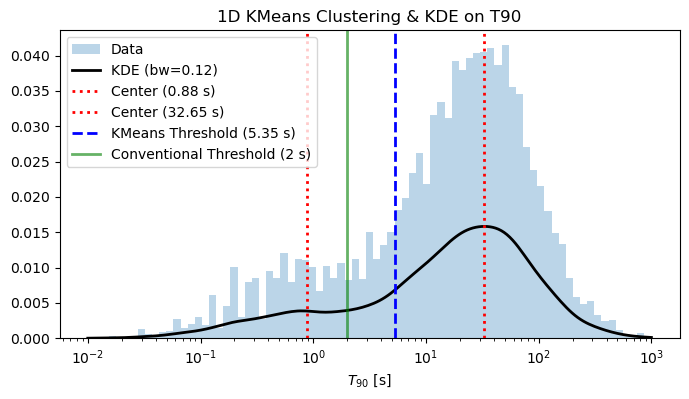

In [11]:
# Clustering 1D su log10(T90) con KMeans e calcolo della soglia (threshold)
clf_1d = KMeans(n_clusters=2, n_init='auto', random_state=42)
clf_1d.fit(skT90)

centers_1d = 10**np.squeeze(clf_1d.cluster_centers_)
labels_1d = clf_1d.predict(skT90)

# Assicuriamoci che il cluster 0 sia sempre quello degli Short GRB (T90 minore)
if centers_1d[0] > centers_1d[1]:
    centers_1d = centers_1d[::-1]
    labels_1d = 1 - labels_1d

# Soglia (threshold) di separazione tra Short e Long GRB in secondi
edge_1d = 10**(np.mean([np.max(skT90[labels_1d == 0]), np.min(skT90[labels_1d == 1])]))
print(f"KMeans 1D Centers: Short = {centers_1d[0]:.2f} s, Long = {centers_1d[1]:.2f} s")
print(f"KMeans 1D Threshold between Short and Long GRBs: {edge_1d:.2f} s (letteratura: ~2 s)")

plt.figure(figsize=(8, 4))
plt.hist(T90_valid, bins=np.logspace(-2, 3, 80), density=False, weights=np.ones(len(T90_valid))/len(T90_valid), alpha=0.3, label='Data')
plt.plot(xgrid, pdf_kde / np.sum(pdf_kde), c='black', lw=2, label=f'KDE (bw={best_bw:.2f})')
for c in centers_1d:
    plt.axvline(c, c='red', ls='dotted', lw=2, label=f'Center ({c:.2f} s)')
plt.axvline(edge_1d, c='blue', ls='dashed', lw=2, label=f'KMeans Threshold ({edge_1d:.2f} s)')
plt.axvline(2.0, c='green', ls='solid', alpha=0.6, lw=2, label='Conventional Threshold (2 s)')
plt.semilogx()
plt.xlabel(r'$T_{90}\ [\mathrm{s}]$')
plt.title('1D KMeans Clustering & KDE on T90')
plt.legend()
plt.show()

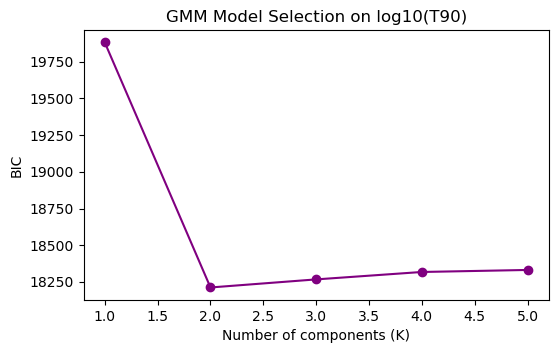

GMM 1D Centers: Short = 0.94 s, Long = 30.46 s
Relative difference in centers (KMeans vs GMM): [0.06186228 0.06924087]

Confusion Matrix (GMM vs KMeans in 1D):
 [[1758    0]
 [ 281 6106]]


In [12]:
# Quante sottopopolazioni ci sono? Controlliamo il BIC al variare di n_components (da 1 a 5)
n_comp = np.arange(1, 6)
bics = [GaussianMixture(n, random_state=42).fit(skT90).bic(skT90) for n in n_comp]

plt.figure(figsize=(6, 3.5))
plt.plot(n_comp, bics, 'o-', color='purple')
plt.xlabel('Number of components (K)')
plt.ylabel('BIC')
plt.title('GMM Model Selection on log10(T90)')
plt.show()

# Fit GMM con 2 componenti
gmm_1d = GaussianMixture(n_components=2, random_state=42).fit(skT90)
means_1d = 10**np.squeeze(gmm_1d.means_)
gmm_labels_1d = gmm_1d.predict(skT90)
responsibilities = gmm_1d.predict_proba(np.log10(xgrid)[:, np.newaxis])

# Riordiniamo affinché 0 = Short GRB, 1 = Long GRB
if means_1d[0] > means_1d[1]:
    means_1d = means_1d[::-1]
    gmm_labels_1d = 1 - gmm_labels_1d
    responsibilities = responsibilities[:, ::-1]

print(f"GMM 1D Centers: Short = {means_1d[0]:.2f} s, Long = {means_1d[1]:.2f} s")
print("Relative difference in centers (KMeans vs GMM):", np.abs(centers_1d - means_1d) / np.mean([centers_1d, means_1d], axis=0))

# Confusion Matrix tra KMeans 1D e GMM 1D
cm_1d = confusion_matrix(gmm_labels_1d, labels_1d)
print("\nConfusion Matrix (GMM vs KMeans in 1D):\n", cm_1d)

In [13]:
# Costruzione matrice 2D: colonna 0 = log10(T90), colonna 1 = log10(Fluence)
X = np.array([log_x_mask, log_y_mask]).T

# Standardizzazione delle feature (media 0, varianza 1) per non distorcere le distanze euclidee
scaler = preprocessing.StandardScaler()
X_scaled = scaler.fit_transform(X)

# 1) KMeans 2D
clf_2d = KMeans(n_clusters=2, n_init='auto', random_state=42)
clf_2d.fit(X_scaled)
centers_2d = scaler.inverse_transform(clf_2d.cluster_centers_)
labels_2d = clf_2d.predict(X_scaled)

if centers_2d[0, 0] > centers_2d[1, 0]:
    centers_2d = centers_2d[::-1]
    labels_2d = 1 - labels_2d

# 2) Gaussian Mixture 2D (con matrice di covarianza completa)
gmm_2d = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
gmm_2d.fit(X)
means_2d = gmm_2d.means_
gmm_labels_2d = gmm_2d.predict(X)

if means_2d[0, 0] > means_2d[1, 0]:
    means_2d = means_2d[::-1]
    gmm_labels_2d = 1 - gmm_labels_2d

print("KMeans 2D Centers (T90 [s], Fluence [erg/cm^2]):")
print("  Short GRB:", 10**centers_2d[0])
print("  Long GRB :", 10**centers_2d[1])
print("\nConfusion Matrix 2D (GMM 2D vs KMeans 2D):\n", confusion_matrix(gmm_labels_2d, labels_2d))

KMeans 2D Centers (T90 [s], Fluence [erg/cm^2]):
  Short GRB: [1.25237399e+00 2.04542516e-07]
  Long GRB : [3.39271230e+01 3.62525553e-06]

Confusion Matrix 2D (GMM 2D vs KMeans 2D):
 [[1800   33]
 [ 442 5730]]


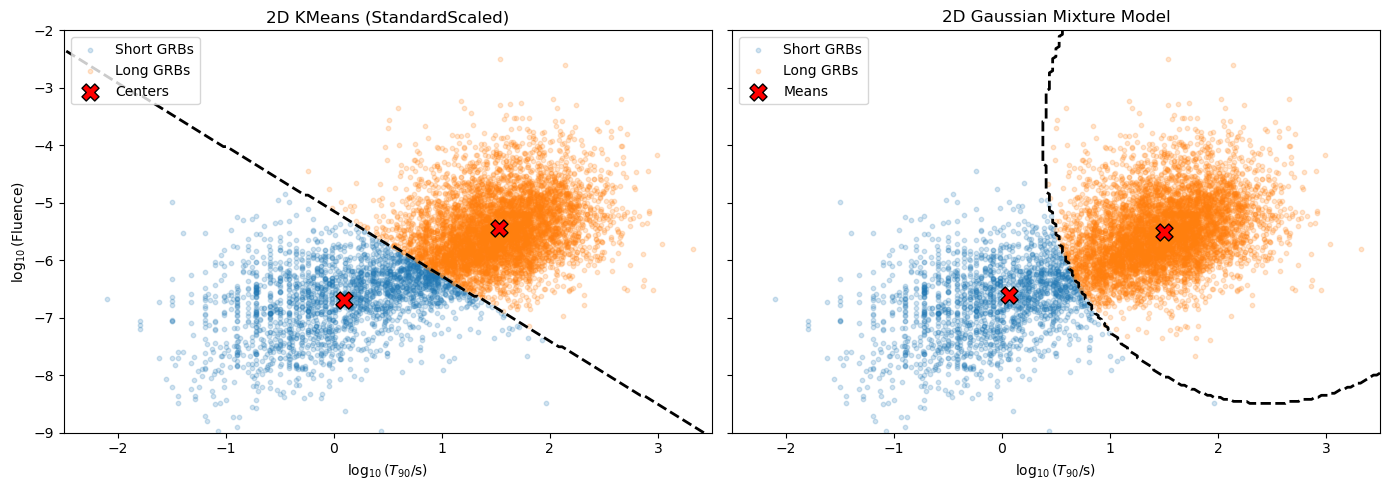

In [14]:
# Plot comparativo 2D: KMeans (con Decision Boundary) vs Gaussian Mixture 2D
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
colors = ['C0', 'C1']
names_cl = ['Short GRBs', 'Long GRBs']

# Griglia per disegnare la Decision Boundary
xx, yy = np.meshgrid(np.linspace(-2.5, 3.5, 200), np.linspace(-9, -2, 200))
grid_2d = np.c_[xx.ravel(), yy.ravel()]

# Pannello 1: KMeans 2D
Z_kmeans = clf_2d.predict(scaler.transform(grid_2d)).reshape(xx.shape)
for ii in range(2):
    ax[0].scatter(X[labels_2d == ii, 0], X[labels_2d == ii, 1], color=colors[ii], alpha=0.2, s=10, label=names_cl[ii])
ax[0].scatter(centers_2d[:, 0], centers_2d[:, 1], color='red', marker='X', s=150, edgecolor='k', zorder=5, label='Centers')
ax[0].contour(xx, yy, Z_kmeans, levels=[0.5], colors='k', linestyles='dashed', linewidths=2)
ax[0].set_title('2D KMeans (StandardScaled)')
ax[0].set_xlabel(r'$\log_{10}(T_{90}/\mathrm{s})$')
ax[0].set_ylabel(r'$\log_{10}(\mathrm{Fluence})$')
ax[0].legend()

# Pannello 2: GMM 2D
Z_gmm = gmm_2d.predict(grid_2d).reshape(xx.shape)
for ii in range(2):
    ax[1].scatter(X[gmm_labels_2d == ii, 0], X[gmm_labels_2d == ii, 1], color=colors[ii], alpha=0.2, s=10, label=names_cl[ii])
ax[1].scatter(means_2d[:, 0], means_2d[:, 1], color='red', marker='X', s=150, edgecolor='k', zorder=5, label='Means')
ax[1].contour(xx, yy, Z_gmm, levels=[0.5], colors='k', linestyles='dashed', linewidths=2)
ax[1].set_title('2D Gaussian Mixture Model')
ax[1].set_xlabel(r'$\log_{10}(T_{90}/\mathrm{s})$')
ax[1].legend()

plt.xlim(-2.5, 3.5)
plt.ylim(-9, -2)
plt.tight_layout()
plt.show()

MeanShift found 3 clusters (main mode + outlier mini-clusters!)


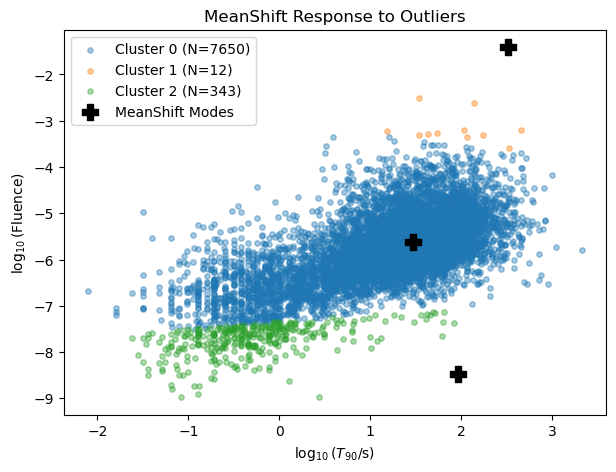

In [15]:
# MeanShift 2D per vedere l'effetto degli outliers
bw_ms = estimate_bandwidth(X_scaled, quantile=0.2, n_samples=1000)
ms = MeanShift(bandwidth=bw_ms, bin_seeding=True, cluster_all=True)
ms.fit(X_scaled)

ms_labels = ms.labels_
ms_centers = scaler.inverse_transform(ms.cluster_centers_)
n_clusters_ms = len(np.unique(ms_labels))
print(f"MeanShift found {n_clusters_ms} clusters (main mode + outlier mini-clusters!)")

plt.figure(figsize=(7, 5))
for k in range(n_clusters_ms):
    my_members = (ms_labels == k)
    plt.scatter(X[my_members, 0], X[my_members, 1], alpha=0.4, s=15, label=f'Cluster {k} (N={np.sum(my_members)})')
plt.scatter(ms_centers[:, 0], ms_centers[:, 1], c='black', marker='P', s=120, label='MeanShift Modes')
plt.xlabel(r'$\log_{10}(T_{90}/\mathrm{s})$')
plt.ylabel(r'$\log_{10}(\mathrm{Fluence})$')
plt.title('MeanShift Response to Outliers')
plt.legend()
plt.show()

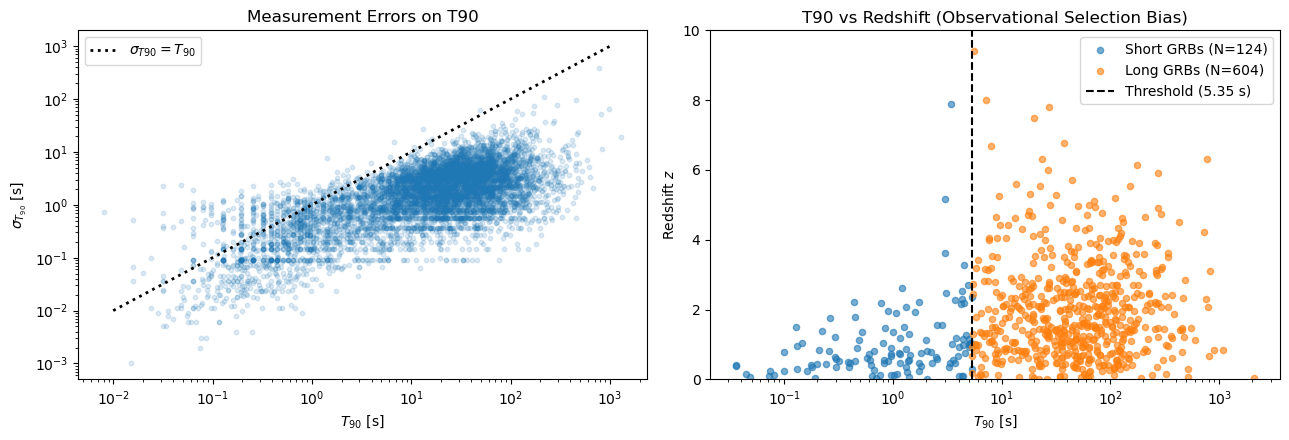

In [16]:
# Estrazione di T90_error (colonna 7) e redshift (colonna 11)
t90_err = data[7].astype(float)
redshift = data[11].astype(float)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Pannello 1: T90 vs T90_error
mask_err = (x > 0) & (t90_err > 0)
ax[0].scatter(x[mask_err], t90_err[mask_err], alpha=0.15, s=10)
ax[0].plot([1e-2, 1e3], [1e-2, 1e3], 'k:', lw=2, label=r'$\sigma_{T90} = T_{90}$')
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel(r'$T_{90}\ [\mathrm{s}]$')
ax[0].set_ylabel(r'$\sigma_{T_{90}}\ [\mathrm{s}]$')
ax[0].set_title('Measurement Errors on T90')
ax[0].legend()

# Pannello 2: T90 vs Redshift (Selection Effects!)
mask_z = (x > 0) & (redshift > 0)
short_z = x[mask_z] < edge_1d
ax[1].scatter(x[mask_z][short_z], redshift[mask_z][short_z], c='C0', alpha=0.6, s=20, label=f'Short GRBs (N={np.sum(short_z)})')
ax[1].scatter(x[mask_z][~short_z], redshift[mask_z][~short_z], c='C1', alpha=0.6, s=20, label=f'Long GRBs (N={np.sum(~short_z)})')
ax[1].axvline(edge_1d, c='k', ls='--', label=f'Threshold ({edge_1d:.2f} s)')
ax[1].set_xscale('log')
ax[1].set_ylim(0, 10)
ax[1].set_xlabel(r'$T_{90}\ [\mathrm{s}]$')
ax[1].set_ylabel('Redshift $z$')
ax[1].set_title('T90 vs Redshift (Observational Selection Bias)')
ax[1].legend()

plt.tight_layout()
plt.show()